# 11c — Jeux globaux : sélection d'équilibre sous information incomplète

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-Python.ipynb) | [Index](README.md) | [12-ReputationGames >>](GameTheory-12-ReputationGames-Python.ipynb)

Un jeu de coordination a **plusieurs équilibres** : deux issues stables, et rien, dans le jeu
lui-même, pour prédire laquelle va se réaliser. Les **jeux globaux** (édifice bayésien de
Harsanyi, puis Carlsson & van Damme (1993), puis Morris & Shin (1998)) lèvent cette indétermination **sans ajouter d'arbre ni
d'action observable** : on donne aux joueurs une *information incomplète partagée* — un état
commun qu'ils ne connaissent que par un **signal bruité** (un *tremble* privé). Dans le modèle étudié, la coupure symétrique devient **unique** sous le niveau critique, et quand le tremble s'amenuise, il **sélectionne** l'issue
cohérente avec l'état fondamental.
**Version jumelle** : [Python](GameTheory-11c-Global-Games-Python.ipynb). Source primaire : carnet Python versionné ; bibliographie héritée sans nouvelle lecture revendiquée. Le port utilise MathNet.Numerics 5.0.0.


## Ce que cet opus ajoute au palier 11

- **Réutilisation de la mécanique 11** : la pièce maîtresse est une **croyance conditionnelle**
  $\mathbb{E}[\theta \mid x]$ — exactement le calcul de Bayes que
  [11](GameTheory-11-BayesianGames-Python.ipynb) pose pour les types privés
  (`get_conditional_prob`, `compute_expected_payoff`). On le déplace ici d'un *type discret*
  vers un *état continu* observé par un signal bruité.
- **Un nouvel usage : la sélection.** [11] calcule un équilibre bayésien *donné* le jeu ;
  [10](GameTheory-10-ForwardInduction-SPE-Python.ipynb) **sélectionne** un équilibre *en forme
  extensive*, en lisant une action observée. Les jeux globaux **sélectionnent en forme normale** :
  la multiplicité se résout par la *structure des croyances* sur un état commun, pas par la
  structure arborescente. C'est l'apport spécifique de ce carnet.


## 1. Le problème : la multiplicité de la coordination

Sur un jeu de coordination, plusieurs profils d'actions sont des équilibres de Nash purs.
Sans autre information, le jeu est **indéterminé** : rien ne dit laquelle des issues pures va
se réaliser. Les jeux globaux ajoutent une broutille d'information — un état commun mal connu —
et le calcul de ce modèle donne une coupure symétrique unique sous le niveau critique, dont la limite, quand le bruit s'amenuise, conduit
vers l'issue *fondamentale*.


## 2. Le modèle — un jeu de coordination perturbé

Deux agents se **coordonnent** sur l'entrée dans un projet commun. La **valeur du projet** est un
**état commun** $\theta \sim \mathcal{N}(0,1)$ que ni l'un ni l'autre ne connaît exactement.
Chacun observe un **signal privé** :

$$x_i = \theta + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)$$

le **tremble** (bruit privé de variance $\sigma^2$). Chacun choisit **Entrer (E)** ou **Rester
(O)**. Entrer rapporte $\theta - m$ si je suis seul, $\theta + m$ si l'autre entre aussi — la
coordination réussie est la plus valueuse — et rester rapporte $0$. Le gain d'entrer est donc
$\theta - m + 2m \cdot \mathbb{1}\{\text{l'autre entre}\}$ : la présence de l'autre
**renforce** mon gain d'entrer, c'est la **complémentarité stratégique** qui fait de ce jeu un
jeu de coordination (et non de congestion). Entrer ensemble est efficace quand $\theta$ est
haut, une perte quand il est bas : la coordination porte sur une décision dont la **valeur
fondamentale** est $\theta$.


**Classe calculée** : les fonctions cherchent les équilibres symétriques en stratégies de seuil. Le seuil de dominance de risque du jeu complet est fixé par les gains ; sa coïncidence avec la moyenne du prior zéro provient ici de la symétrie.


In [1]:
#r "nuget: MathNet.Numerics,5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using MathNet.Numerics.Distributions;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
record Svg(string Content);
Formatter.Register<Svg>((plot, writer) => writer.Write(plot.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
const double m = 1.0;
// La postérieure gaussienne et le signal adverse intègrent l'incertitude sur theta.
double Mu(double x, double sigma) => x / (1 + sigma * sigma);
double Variance(double sigma) => sigma * sigma / (1 + sigma * sigma);
double POther(double x, double cutoff, double sigma) =>
    Normal.CDF(0, 1, (Mu(x, sigma) - cutoff) / Math.Sqrt(sigma * sigma + Variance(sigma)));
double Payoff(double x, double cutoff, double sigma) =>
    Mu(x, sigma) - m + 2 * m * POther(x, cutoff, sigma);
Console.WriteLine($"MathNet {typeof(Normal).Assembly.GetName().Version} ; m={m} ; postérieure et gain définis.");


Installed Packages MathNet.Numerics, 5.0.0

MathNet 5.0.0.0 ; m=1 ; postérieure et gain définis.


**Ces quatre fonctions sont le cœur bayésien** : `Mu` est la croyance
$\mathbb{E}[\theta \mid x]$, `POther` est la croyance sur l'action de l'autre
conditionnelle au signal. C'est la mécanique de [11], transposée à un état continu.

La différence avec un jeu de congestion tient au **signe** du terme de croyance : ici
`+ 2m · P(l'autre entre)`, car l'entrée de l'autre **complète** la mienne (complémentarité).
Ce signe fait de `Payoff` une fonction **croissante** de mon signal $x$ — un signal haut
rend l'entrée plus attractive — et c'est exactement la condition pour qu'une stratégie seuil
soit un équilibre de Nash bayésien.


In [2]:
// La bissection conserve le budget de 200 itérations de la source.
double Indifference(double c, double sigma) => Payoff(c, c, sigma);
double? SolveCutoff(double sigma, double lo = -8, double hi = 8)
{
    if (Indifference(lo, sigma) * Indifference(hi, sigma) > 0)
        return null;
    for (int i = 0; i < 200; i++)
    {
        double mid = (lo + hi) / 2;
        if (Indifference(mid, sigma) > 0)
            hi = mid;
        else
            lo = mid;
    }
    return (lo + hi) / 2;
}
foreach (double s in new[] { 1.0, .5, .3, .1, .05, .01, .001 })
    Console.WriteLine($"sigma={s:G4} seuil={SolveCutoff(s):F4}");


sigma=1 seuil=0.0000


sigma=0.5 seuil=0.0000


sigma=0.3 seuil=0.0000


sigma=0.1 seuil=0.0000


sigma=0.05 seuil=0.0000


sigma=0.01 seuil=0.0000


sigma=0.001 seuil=0.0000


### Contrôle de meilleure réponse

Vérifions le signe des gains de part et d’autre du seuil calculé.


In [3]:
// Une racine est contrôlée par les gains de part et d'autre du seuil.
double sigma = .1,
    c = SolveCutoff(sigma).Value;
double below = Payoff(c - .01, c, sigma),
    above = Payoff(c + .01, c, sigma),
    derivative = (above - below) / .02;
if (!(below < 0 && above > 0))
    throw new Exception("Meilleure réponse violée");
Console.WriteLine(
    $"sigma={sigma} seuil={c:F6} ; dessous={below:+0.000000;-0.000000}, dessus={above:+0.000000;-0.000000}, dérivée={derivative:F4}"
);


sigma=0.1 seuil=0.000000 ; dessous=-0.065854, dessus=+0.065854, dérivée=6.5854


La structure d'équilibre est **théoriquement** une stratégie seuil : chacun entre au-delà
d'un seuil $c^*(\sigma)$ de son signal. La résoudre, c'est trouver le signal où le joueur est
**indifférent** entre entrer et rester — une seule inconnue, une seule équation.


## Exercices

Les fonctions restent ouvertes et les sondes vérifient les réponses.


### Exercice 1 — le seuil d'équilibre

Reproduire la résolution de l'équilibre : pour un tremble donné, retourner le seuil BNE
$c^*(\sigma)$.


In [4]:
// Exercice 1 : déterminer le seuil pour un bruit donné.
Func<double, double?> seuilBayesien = s =>
{
    // TODO : utiliser la résolution d'indifférence.
    return null;
};
var cases1 = new[] { .1, .5, 1.0 };
var answers1 = cases1.Select(seuilBayesien).ToArray();
if (answers1.All(x => x == null))
    Console.WriteLine("Exercice 1 à compléter");
else
{
    for (int i = 0; i < cases1.Length; i++)
        if (
            answers1[i] == null
            || !double.IsFinite(answers1[i].Value)
            || Math.Abs(answers1[i].Value - SolveCutoff(cases1[i]).Value) > 1e-9
        )
            throw new Exception("Seuil incorrect ou réponse partielle");
    Console.WriteLine("Exercice 1 : seuils vérifiés");
}


Exercice 1 à compléter


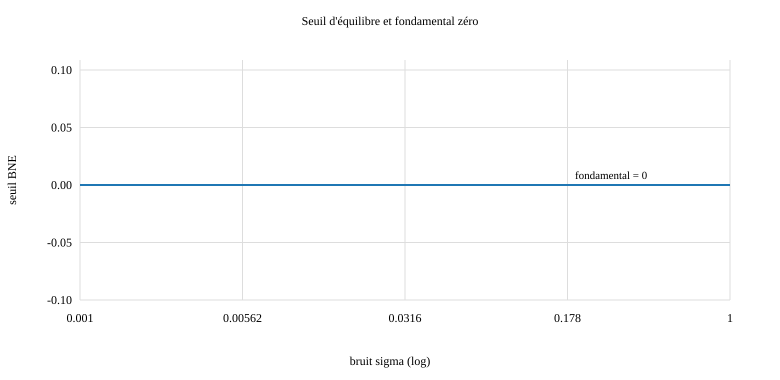

In [5]:
// Tracé SVG : axe logarithmique des 60 bruits et référence horizontale zéro.
string Chart(
    double[] xs,
    double[] ys,
    string title,
    string xlabel,
    string ylabel,
    bool logX = false,
    double? vertical = null
)
{
    double[] xx = logX ? xs.Select(Math.Log10).ToArray() : xs;
    double xmin = xx.Min(),
        xmax = xx.Max();
    double ymin = Math.Min(0, ys.Min()),
        ymax = Math.Max(1e-6, ys.Max());
    if (ymax - ymin < 1e-5)
    {
        ymin = -.1;
        ymax = .1;
    }
    else
    {
        double pad = (ymax - ymin) * .08;
        ymin -= pad;
        ymax += pad;
    }
    double X(double x) => 80 + (x - xmin) / (xmax - xmin) * 650;
    double Y(double y) => 300 - (y - ymin) / (ymax - ymin) * 230;
    var sb = new StringBuilder(
        $"<svg xmlns='http://www.w3.org/2000/svg' width='780' height='380'>"
        + $"<rect width='100%' height='100%' fill='white'/>"
        + $"<text x='390' y='25' text-anchor='middle'>{title}</text>"
        + $"<text x='390' y='365' text-anchor='middle'>{xlabel}</text>"
        + $"<text transform='translate(16,180) rotate(-90)' text-anchor='middle'>{ylabel}</text>"
    );
    for (int i = 0; i <= 4; i++)
    {
        double a = xmin + (xmax - xmin) * i / 4,
            b = ymin + (ymax - ymin) * i / 4;
        sb.Append(
            $"<line x1='{X(a):F2}' y1='60' x2='{X(a):F2}' y2='300' stroke='#ddd'/><text x='{X(a):F2}' y='322' font-size='12' text-anchor='middle'>{(logX ? Math.Pow(10, a) : a):G3}</text>"
        );
        sb.Append(
            $"<line x1='80' y1='{Y(b):F2}' x2='730' y2='{Y(b):F2}' stroke='#ddd'/><text x='72' y='{Y(b) + 4:F2}' font-size='12' text-anchor='end'>{b:F2}</text>"
        );
    }
    if (vertical.HasValue)
        sb.Append(
            $"<line x1='{X(logX ? Math.Log10(vertical.Value) : vertical.Value):F2}' y1='60' "
            + $"x2='{X(logX ? Math.Log10(vertical.Value) : vertical.Value):F2}' y2='300' stroke='#777' stroke-dasharray='4 4'/>"
        );
    if (logX)
        sb.Append(
            $"<line x1='80' y1='{Y(0):F2}' x2='730' y2='{Y(0):F2}' stroke='#888' stroke-dasharray='4 4'/><text x='575' y='{Y(0) - 6:F2}' font-size='11'>fondamental = 0</text>"
        );
    if (vertical.HasValue)
        sb.Append(
            $"<text x='{X(logX ? Math.Log10(vertical.Value) : vertical.Value) + 5:F2}' y='75' font-size='11'>theta=0</text>"
        );
    var points = string.Join(" ", xx.Select((x, i) => $"{X(x):F2},{Y(ys[i]):F2}"));
    sb.Append($"<polyline points='{points}' fill='none' stroke='#1f77b4' stroke-width='2'/></svg>");
    return sb.ToString();
}
var sigmas = Enumerable.Range(0, 60).Select(i => .001 + (1 - .001) * i / 59).ToArray();
var cutoffs = sigmas.Select(s => SolveCutoff(s).Value).ToArray();
display(
    new Svg(
        Chart(
            sigmas,
            cutoffs,
            "Seuil d'équilibre et fondamental zéro",
            "bruit sigma (log)",
            "seuil BNE",
            true
        )
    )
);


**Lecture.** Par symétrie du modèle, zéro est une racine pour tout bruit ; dans la plage étudiée sous le niveau critique, c'est l'unique seuil mesuré. Quand le tremble s'amenuise, l'issue
d'équilibre devient une fonction de l'état réel $\theta$ — plus des croyances subjectives.
C'est le théorème : l'équilibre unique des jeux globaux (tremble sous le niveau critique)
**sélectionne** l'issue fondamentale (coordonner quand $\theta > 0$) — une sélection
**par dominance de risque**, dont on précisera la portée et son écart à l'efficacité juste après.

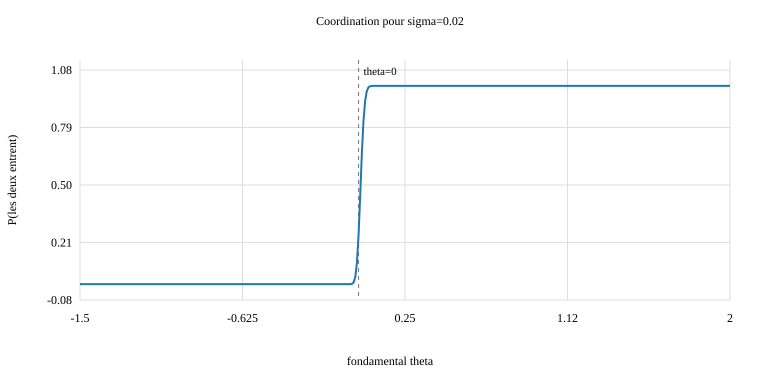

In [6]:
// Deux signaux indépendants conditionnellement à theta donnent le carré de la probabilité.
sigma = .02;
c = SolveCutoff(sigma).Value;
var thetas = Enumerable.Range(0, 400).Select(i => -1.5 + 3.5 * i / 399).ToArray();
var both = thetas.Select(t => Math.Pow(Normal.CDF(0, 1, (t - c) / sigma), 2)).ToArray();
display(
    new Svg(
        Chart(
            thetas,
            both,
            "Coordination pour sigma=0.02",
            "fondamental theta",
            "P(les deux entrent)",
            false,
            0
        )
    )
);


**Lecture.** La probabilité de **coordonner sur l'entrée** passe de 0 à 1, franchement, au
seuil fondamental $0$ (la moyenne de $\theta$). Le tremble $\to 0$ **sélectionne** coordonner
quand $\theta > 0$ — là où le jeu sans tremble laissait plusieurs issues stables. La sélection
est **lisible dans l'état**, pas dans les croyances.

Elle est une sélection **par dominance de risque** (Harsanyi–Selten), pas une sélection
d'efficacité. Trois notions, trois seuils : « entrer à deux » est **pareto-préférable** à
« rester à deux » dès que $\theta + m > 0$, c'est-à-dire pour $\theta > -m$ — c'est la
frontière **efficace** (Pareto), qui ne décide pas de la sélection ; l'action « entrer »
**domine strictement** « rester » (gain supérieur quelle que soit l'action de l'autre)
seulement pour $\theta > m$ ; le jeu global, lui, **sélectionne** au fondamental, $\theta = 0$.
Il n'atteint pas la frontière efficace — il s'arrête à la moyenne du fondamental, $\theta = 0$.
Contre-exemple, $m = 1$ : à $\theta = -0{,}5$, entrer à deux rapporte
$-0{,}5 + 1 = +0{,}5 > 0$ à chacun, donc c'est **efficace** ; et pourtant l'équilibre
sélectionné prescrit **rester** ($-0{,}5 < 0$). La sélection par jeu global est
**conservatrice** par rapport à l'efficacité : elle retient l'issue **sélectionnée par
dominance de risque**, pas toute la région où elle est pareto-préférable.

### Exercice 2 — la probabilité de coordination

Écrire la fonction qui, **donné** un état fondamental $\theta$, un seuil $c$ et un tremble
$\sigma$, retourne $P(\text{les deux entrent} \mid \theta)$.


In [7]:
// Exercice 2 : probabilité que les deux signaux dépassent le seuil.
Func<double, double, double, double?> probCoordonner = (theta, cutoff, s) =>
{
    // TODO : combiner les deux probabilités conditionnellement indépendantes.
    return null;
};
var cases2 = new[] { (-.5, 0.0, .3), (.2, .4, .7), (1.0, .5, .1) };
var answers2 = cases2.Select(x => probCoordonner(x.Item1, x.Item2, x.Item3)).ToArray();
if (answers2.All(x => x == null))
    Console.WriteLine("Exercice 2 à compléter");
else
{
    for (int i = 0; i < cases2.Length; i++)
    {
        var (t, k, s) = cases2[i];
        double expected = Math.Pow(Normal.CDF(0, 1, (t - k) / s), 2);
        if (
            answers2[i] == null
            || !double.IsFinite(answers2[i].Value)
            || Math.Abs(answers2[i].Value - expected) > 1e-10
        )
            throw new Exception("Probabilité incorrecte ou réponse partielle");
    }
    Console.WriteLine("Exercice 2 : probabilités vérifiées");
}


Exercice 2 à compléter


In [8]:
// 121 points mesurent les changements de signe sur [-6,6].
foreach (double s in new[] { .1, 1, 2 })
{
    double d = (Indifference(.01, s) - Indifference(-.01, s)) / .02;
    var values = Enumerable
        .Range(0, 121)
        .Select(i => Indifference(-6 + i * .1, s))
        .Where(v => v != 0)
        .ToArray();
    int changes = Enumerable
        .Range(1, values.Length - 1)
        .Count(i => Math.Sign(values[i]) != Math.Sign(values[i - 1]));
    Console.WriteLine(
        $"sigma={s:F2} H'(0)={d:+0.0000;-0.0000}, changements={changes} ; {(d > 0 ? "unique dans ce modèle" : "multiplicité mesurée")}"
    );
}


sigma=0.10 H'(0)=+0.9341, changements=1 ; unique dans ce modèle


sigma=1.00 H'(0)=+0.1743, changements=1 ; unique dans ce modèle


sigma=2.00 H'(0)=-0.0913, changements=3 ; multiplicité mesurée


**Portée du résultat.** On calcule les équilibres symétriques en stratégies de seuil, avec le prior centré de ce carnet. En posant $\lambda=1/(1+\sigma^2)$ et $a=(1-\lambda)/\sqrt{\sigma^2+\sigma^2/(1+\sigma^2)}$, l'indifférence s'écrit $H(c)=\lambda c-m+2m\Phi(-ac)$. Sa dérivée $H'(c)=\lambda-2ma\phi(ac)$ est minimale en zéro, car la densité normale y est maximale. Ainsi $H'(0)>0$ établit ici la croissance stricte sur toute la droite, et donc l'unique racine zéro, puisque H est impaire. Ce raisonnement dépasse le seul comptage sur une grille, mais reste propre à ce modèle.

La condition change de signe au bruit critique d'environ `1,442457`. Au-dessus, H décroît près de zéro et croît dans les queues : ses deux extrema et son caractère impair donnent trois racines. La grille de 121 points illustre cette multiplicité pour `σ=2` ; elle ne démontre pas une unicité universelle des jeux globaux ni une stabilité dynamique. La frontière de risque du jeu complet reste `θ=0`.

### Exercice 3 — l'effet d'un a priori décalé

Si le prior devient $\theta\sim\mathcal{N}(\mu_0,1)$, mesurez le **seuil BNE au bruit fini demandé** avec `seuilFondamental`. La moyenne a posteriori se déplace, donc cette coupure peut changer avec $\mu_0$ et $\sigma$.

Distinguez-la de la frontière de **dominance de risque du jeu à information complète**, qui reste $\theta=0$ parce que les gains sont toujours $\theta\pm m$. Recalculez l'indifférence avec le prior décalé ; comparez le seuil à la moyenne $\mu_0$ et à sa limite lorsque le bruit tend vers zéro. Le nom historique de la fonction désigne ici cette coupure BNE finie, pas un déplacement de la frontière de risque.


In [9]:
// Exercice 3 : résoudre le seuil au prior de moyenne mu0.
Func<double, double, double?> seuilFondamental = (mu0, s) =>
{
    // TODO : recomposer la postérieure et résoudre l'indifférence.
    return null;
};
var cases3 = new[] { (.5, .3), (-.7, .4), (1.0, .2) };
var answers3 = cases3.Select(x => seuilFondamental(x.Item1, x.Item2)).ToArray();
if (answers3.All(x => x == null))
    Console.WriteLine("Exercice 3 à compléter");
else
{
    for (int i = 0; i < cases3.Length; i++)
    {
        var (mu0, s) = cases3[i];
        var answer = answers3[i];
        if (answer == null || !double.IsFinite(answer.Value))
            throw new Exception("Réponse partielle ou non finie");
        double v = s * s / (1 + s * s),
            posterior = (answer.Value + mu0 * s * s) / (1 + s * s);
        double residual =
            posterior
            - m
            + 2 * m * Normal.CDF(0, 1, (posterior - answer.Value) / Math.Sqrt(s * s + v));
        if (Math.Abs(residual) > 1e-9)
            throw new Exception("Indifférence décalée incorrecte");
    }
    Console.WriteLine("Exercice 3 : priors décalés vérifiés");
}


Exercice 3 à compléter


## 4. Ce que la sélection par jeu global fait que l'induction en avant ne fait pas

[10](GameTheory-10-ForwardInduction-SPE-Python.ipynb) **sélectionne** en lisant une *action
observée* dans un *arbre* : renoncer à une option extérieure est un signal sur les
intentions. La sélection par **jeu global** n'a ni arbre ni action observée : elle naît de la
*structure des croyances* sur un état commun. Deux instruments de sélection, deux logiques —
l'un temporelle (forme extensive), l'autre informationnelle (forme normale). Le jeu global est
l'outil quand la coordination est **simultanée** et que l'indétermination vient de
l'information, pas de l'ordre des coups.


### Sans dominance de risque, pas de sélection

Tout ce qui précède repose sur un fait qu'on n'a pas encore mis en avant — et qu'il faut
séparer net de l'efficacité. Ce jeu de coordination **possède une structure de dominance de
risque** : il y a une issue que le tremble va privilégier. Trois notions, qui ne coïncident
que par morceaux :

- **Supériorité de Pareto (efficacité).** « Entrer à deux » est **pareto-préférable** à
  « rester à deux » dès que chacun y gagne : $\theta + m > 0$, c'est-à-dire pour
  $\theta > -m$. C'est la frontière **efficace** — à elle seule, elle ne dit pas laquelle
  des deux issues stables le jeu retiendra.
- **Dominance de risque (Harsanyi–Selten).** C'est la structure que le jeu global **lit
  réellement** : la limite tremble $\to 0$ retient l'issue dont la région d'attraction,
  mesurée en risque, l'emporte. Dans **ce** modèle symétrique, ce seuil se déduit des
  gains et de la symétrie : il tombe sur la moyenne du fondamental, $\theta = 0$ —
  **au-dessus** de la frontière de Pareto. Ce n'est pas une définition générale de la
  dominance de risque : la position du seuil dépend des gains du jeu.
- **Dominance stratégique stricte.** L'action « entrer » **domine strictement** « rester »
  (au sens de l'élimination itérée des stratégies dominées) seulement si elle rapporte plus
  quelle que soit l'action de l'autre : $\theta + m > 0$ **et** $\theta - m > 0$,
  c'est-à-dire pour $\theta > m$. C'est la condition la plus exigeante des trois : pour $m > 0$ les seuils s'ordonnent $-m < 0 < m$ et les ensembles qu'ils délimitent sont emboîtés — mais elle ne définit pas l'issue retenue, que le jeu sélectionne sur $\theta > 0$.

Sans cette structure de dominance de risque — un jeu où les deux issues stables restent
incomparables **en risque** quel que soit l'état — l'argument du jeu global ne désigne
aucune issue privilégiée. Ce carnet ne traite pas ce cas et ne l'affirme pas. Ce qu'il
établit est plus étroit, et c'est ce qui sépare les trois notions : sur le modèle
symétrique ci-dessus, la limite tremble $\to 0$ suit le seuil de dominance de risque
($\theta = 0$), déduit des gains, et non la frontière de Pareto ($\theta = -m$). La
sélection par jeu global n'est donc pas un effet du bruit ; elle **lit** la dominance de
risque. Ce constat porte sur le modèle calculé ici : rien dans ce carnet n'établit qu'une
telle sélection existe hors des jeux où la dominance de risque départage les issues
(cf. #21801).


## Références

- Carlsson, H., & van Damme, E. (1993). « Global Games and Equilibrium Selection », *Econometrica* 61(5), 989–1018. — Introduction du **jeu global** : un état tiré d'une classe de jeux, observé avec bruit par chaque joueur ; quand le bruit s'annule, l'élimination itérée des stratégies dominées sélectionne l'équilibre de **dominance de risque** (critère de Harsanyi–Selten).
- Morris, S., & Shin, H. S. (1998). « Unique Equilibrium in a Model of Self-Fulfilling Currency Attacks », *American Economic Review* 88(3), 587–597. — L'application canonique du programme de Carlsson & van Damme : un équilibre **unique** en seuil d'attaque, sélectionné par le bruit privé.

L'ordre chronologique fait foi : le concept de jeu global est dû à **Carlsson & van Damme (1993)**, qui s'appuient sur l'édifice bayésien de Harsanyi (1967–1968) ; **Morris & Shin (1998)** en ont donné l'application de référence et la popularisation.